# EU REGIONAL CONVERGENCE ANALYSIS
## An analysis of GDP and employment convergence across EU NUTS 2 regions, from 2016 to 2024

## INTRODUCTION

European Union regions do not have the same level of economic growth. Some regions have high income and strong employment. Other regions have lower income and fewer job opportunities. These differences can affect the lives of people and the development of each region. This project studies whether the economic gaps between European Union regions became smaller or larger from 2016 to 2024. The analysis uses data from Eurostat. It focuses on 244 NUTS 2 regions. A NUTS 2 region is an area used by the European Union to collect and compare regional data. The project uses GDP per person, employment rates, and unemployment rates. GDP is measured in purchasing power standards. This makes comparisons between countries aligned because prices differ across the European Union. The analysis answers four questions. First, it checks whether the spread between regions became smaller each year. Second, it tests whether poorer regions grew faster than richer regions. Third, it groups regions that have similar economic and employment results. It also checks whether these groups are linked to location or the type of economic activity in each region. Finally, it compares two convergence tests and explains why the results may agree or disagree. The results can help in understanding whether European Union regions are becoming more equal over time.

## Setup

In [1]:
from pathlib import Path
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 4)


def locate_project_root():
    cwd = Path.cwd().resolve()
    candidates = [cwd, *cwd.parents]
    for candidate in candidates:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError(
        "Project root not found. Open this notebook inside the EU_Regional_Convergence_Project repository."
    )

ROOT = locate_project_root()
DATA = ROOT / "data"
OUTPUTS = ROOT / "outputs"
SRC = ROOT / "src"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


def show_image(path, width=900):
    path = Path(path)
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"Visual not found: {path}. Run the relevant analysis script first.")


def show_csv(path, columns=None, decimals=3, index_col=None):
    path = Path(path)
    if not path.exists():
        print(f"Table not found: {path}. Run the relevant analysis script first.")
        return None
    frame = pd.read_csv(path, index_col=index_col)
    if columns is not None:
        columns = [col for col in columns if col in frame.columns]
        frame = frame[columns]
    display(frame.round(decimals))
    return frame

print("Project root:", ROOT)
print("Data folder:", DATA)
print("Outputs folder:", OUTPUTS)

Project root: /Users/felix/EU_Regional_Convergence_Project
Data folder: /Users/felix/EU_Regional_Convergence_Project/data
Outputs folder: /Users/felix/EU_Regional_Convergence_Project/outputs


## Group analysis pipelines

In [2]:
from runpy import run_path

pipeline_candidates = {
    "RQ1A GDP dispersion": [SRC / "rq1a_dispersion.py"],
    "RQ1B employment dispersion": [SRC / "rq1b_employment_dispersion.py", SRC / "rq1b_report.py"],
    "RQ2 beta convergence": [SRC / "12_rq2_beta_convergence.py", SRC / "rq2_beta_convergence.py"],
    "RQ4 sigma versus beta": [SRC / "11_rq4_sigma_vs_beta.py", SRC / "rq4_sigma_vs_beta.py"],
}

for label, candidates in pipeline_candidates.items():
    script = next((p for p in candidates if p.exists()), None)
    if script is None:
        print(f"SKIPPED: {label}. No matching source script was found.")
        continue
    print(f"RUNNING: {label} -> {script.name}")
    try:
        if script.name == "rq1a_dispersion.py":
            from src.rq1a_dispersion import main as rq1a_main
            rq1a_main(DATA / "eu_nuts2_master_panel.csv", OUTPUTS / "rq1a")
        else:
            run_path(str(script), run_name="__main__")
        print(f"COMPLETED: {label}")
    except Exception as exc:
        print(f"WARNING: {label} did not complete: {exc}")

RUNNING: RQ1A GDP dispersion -> rq1a_dispersion.py
SKIPPED: RQ1B employment dispersion. No matching source script was found.
RUNNING: RQ2 beta convergence -> 12_rq2_beta_convergence.py
Regions: 244
Years: 2016 to 2024
Duplicate region-year rows: 0

RESULTS (slope < 0 means poorer regions grew faster)
                       model  n_regions   slope  se_cluster  p_value  r_squared  speed  half_life_yrs
              A. Full sample        244 -0.0167      0.0045   0.0002     0.2371 0.0179        38.7851
      B. Excl. commuter ring        237 -0.0168      0.0045   0.0002     0.2412 0.0180        38.4473
       B2. Excl. core + ring        230 -0.0191      0.0043   0.0000     0.3002 0.0207        33.4276
 C. Excl. break-flag regions        223 -0.0152      0.0051   0.0028     0.1937 0.0162        42.7837
D. Excl. influential regions        228 -0.0182      0.0032   0.0000     0.3691 0.0196        35.3119
            E. End year 2023        244 -0.0167      0.0047   0.0004     0.2206 0.0177

## LITERATURE REVIEW

Regional convergence means that poorer regions move closer to richer regions over time. This can happen when poorer regions grow faster or when the economic gap between regions becomes smaller. Studies show that this process is not equal across the European Union. Kostadinović and Stanković (2025) studied income differences across EU NUTS 2 regions. The findings showed strong convergence in newer EU member states. However, some older member states showed signs of divergence. The study also found that education, investment, migration, and geography can affect regional growth. Fiorelli et al. (2024) studied 249 European regions from 2000 to 2021. The authors found that regional inequality fell over time, especially in poorer countries. The authors also identified three regional groups. This supports the use of clustering to find regions with similar patterns. Cieślik and Misiak (2025) studied regions in Poland at NUTS 1, NUTS 2, and NUTS 3 levels. The results did not show full convergence. Instead, different groups of regions moved towards different income levels. This shows that national growth does not always reduce all regional gaps. Mockevičienė and Butkus (2026) reviewed 33 studies on EU financial support. The review found mixed results. EU funding may support growth, but its effect depends on the region and the type of support. These studies show that convergence can be slow and uneven.

Recent studies give more evidence that regional convergence is uneven across Europe. Leško et al. (2026) studied 242 NUTS 2 regions from 2000 to 2022. The study found overall convergence, but the regions did not follow one common path. The regions formed three groups with different growth patterns. Some poorer regions caught up strongly. Other regions showed weak or slow progress, even when they received large amounts of EU support. This finding shows that funding alone may not produce the same result in every region. Local economic conditions also matter. Truglia and Zeli (2025) studied regional convergence in the euro area from 2001 to 2018. The results showed divergence between some regions. The authors also found a clear difference between stronger central regions and weaker outer regions. Cieślik and Misiak (2025) studied NUTS 3 regions in the Visegrad-4 countries. The study rejected full convergence across all regions. Instead, three convergence groups were found. Large city regions formed one group, nearby regions formed another group, and poorer outer regions formed a third group. This shows that location and access to large cities can affect regional growth. Butkus et al. (2026) studied employment and unemployment across 244 NUTS 2 regions from 1999 to 2024. The study found some employment catch-up, but unemployment patterns remained very different. Nearby regions also affected one another. Together, these studies show that convergence is shaped by income, employment, location, regional structure, and links with nearby regions. They support the use of sigma convergence, beta convergence, and regional clustering in this project.

# 1. SIGMA CONVERGENCE
A focus on whether the spread in regional outcomes becomes smaller over time.

## 1.1. Is the GDP spread narrowing year by year?

The GDP analysis uses the coefficient of variation, standard deviation, percentile gaps, period comparisons, and sensitivity checks.

,year,n_regions,cv_pct,sd,p90_p10_gap,cv_pct_change,sd_change,p90_p10_gap_change
0,2016,244,39.77,37.56,88.7,NaN,NaN,NaN
1,2017,244,39.51,37.25,90.1,-0.27,-0.31,1.4
2,2018,244,39.27,36.98,90.7,-0.24,-0.27,0.6
3,2019,244,38.57,36.23,85.7,-0.70,-0.74,-5.0
4,2020,244,39.43,37.15,85.7,0.86,0.92,0.0
5,2021,244,39.69,37.35,83.0,0.26,0.20,-2.7
6,2022,244,39.93,37.67,84.0,0.24,0.32,1.0
7,2023,244,38.02,35.81,79.4,-1.90,-1.86,-4.6
8,2024,244,37.96,35.69,75.7,-0.07,-0.12,-3.7


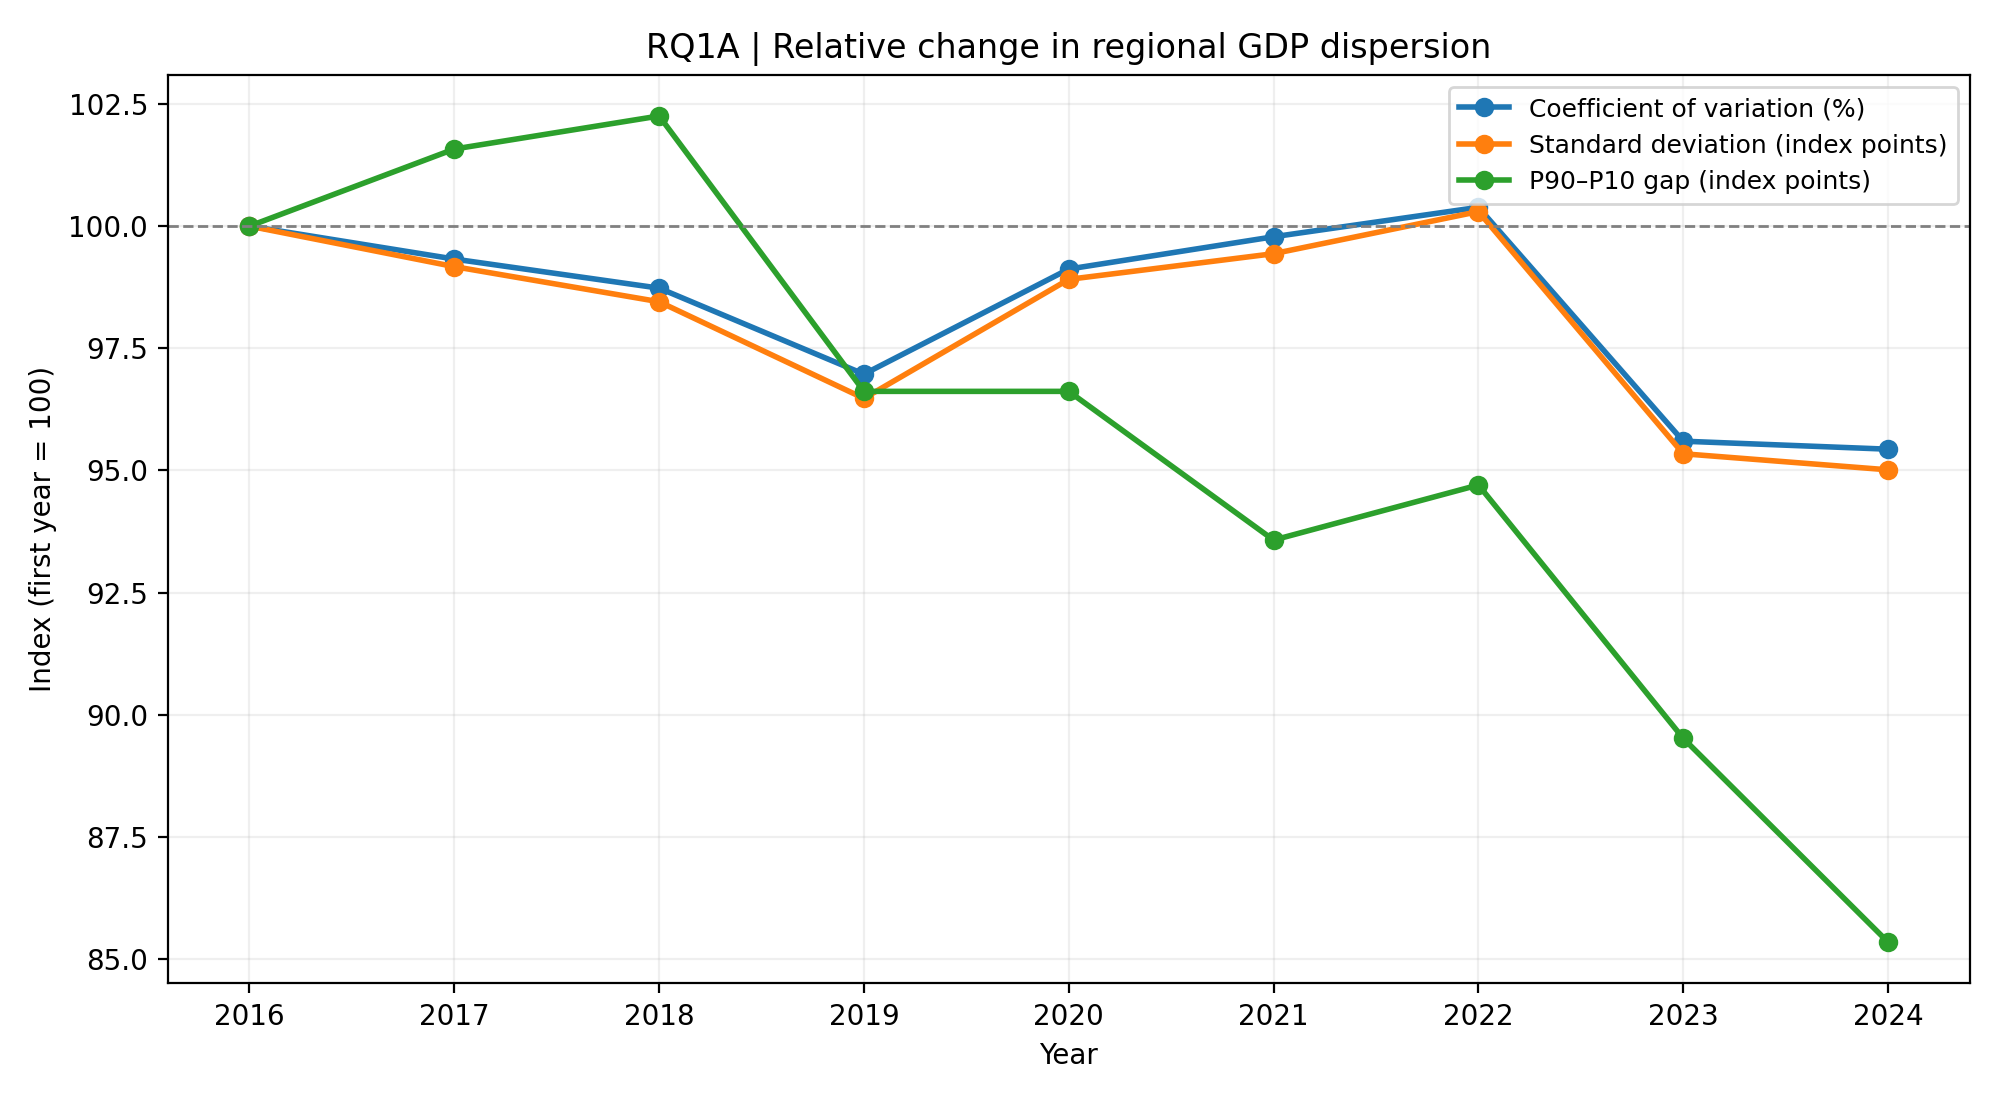

In [3]:
rq1a_out = OUTPUTS / "rq1a"
rq1a_annual = show_csv(
    rq1a_out / "annual_dispersion_enhanced.csv",
    ["year", "n_regions", "cv_pct", "sd", "p90_p10_gap", "cv_pct_change", "sd_change", "p90_p10_gap_change"],
    decimals=2,
)
show_image(rq1a_out / "figure_1_indexed_dispersion.png")

The results show overall GDP convergence between EU regions from 2016 to 2024. By 2024, the coefficient of variation was about 95% of its 2016 level. The standard deviation also fell to about 95%. The gap between the richest and poorest groups fell more strongly, reaching about 85% of its starting level. However, the gap did not fall every year. GDP differences increased slightly between 2019 and 2022 before falling sharply in 2023 and 2024. This means that convergence was real, but uneven. The result supports Kostadinović and Stanković (2025), who found declining income differences in many EU regions. It also agrees with Leško et al. (2026), who found overall convergence but different growth paths across regional groups. Therefore, the answer to the first research question is yes, but regional GDP gaps did not narrow in every year.

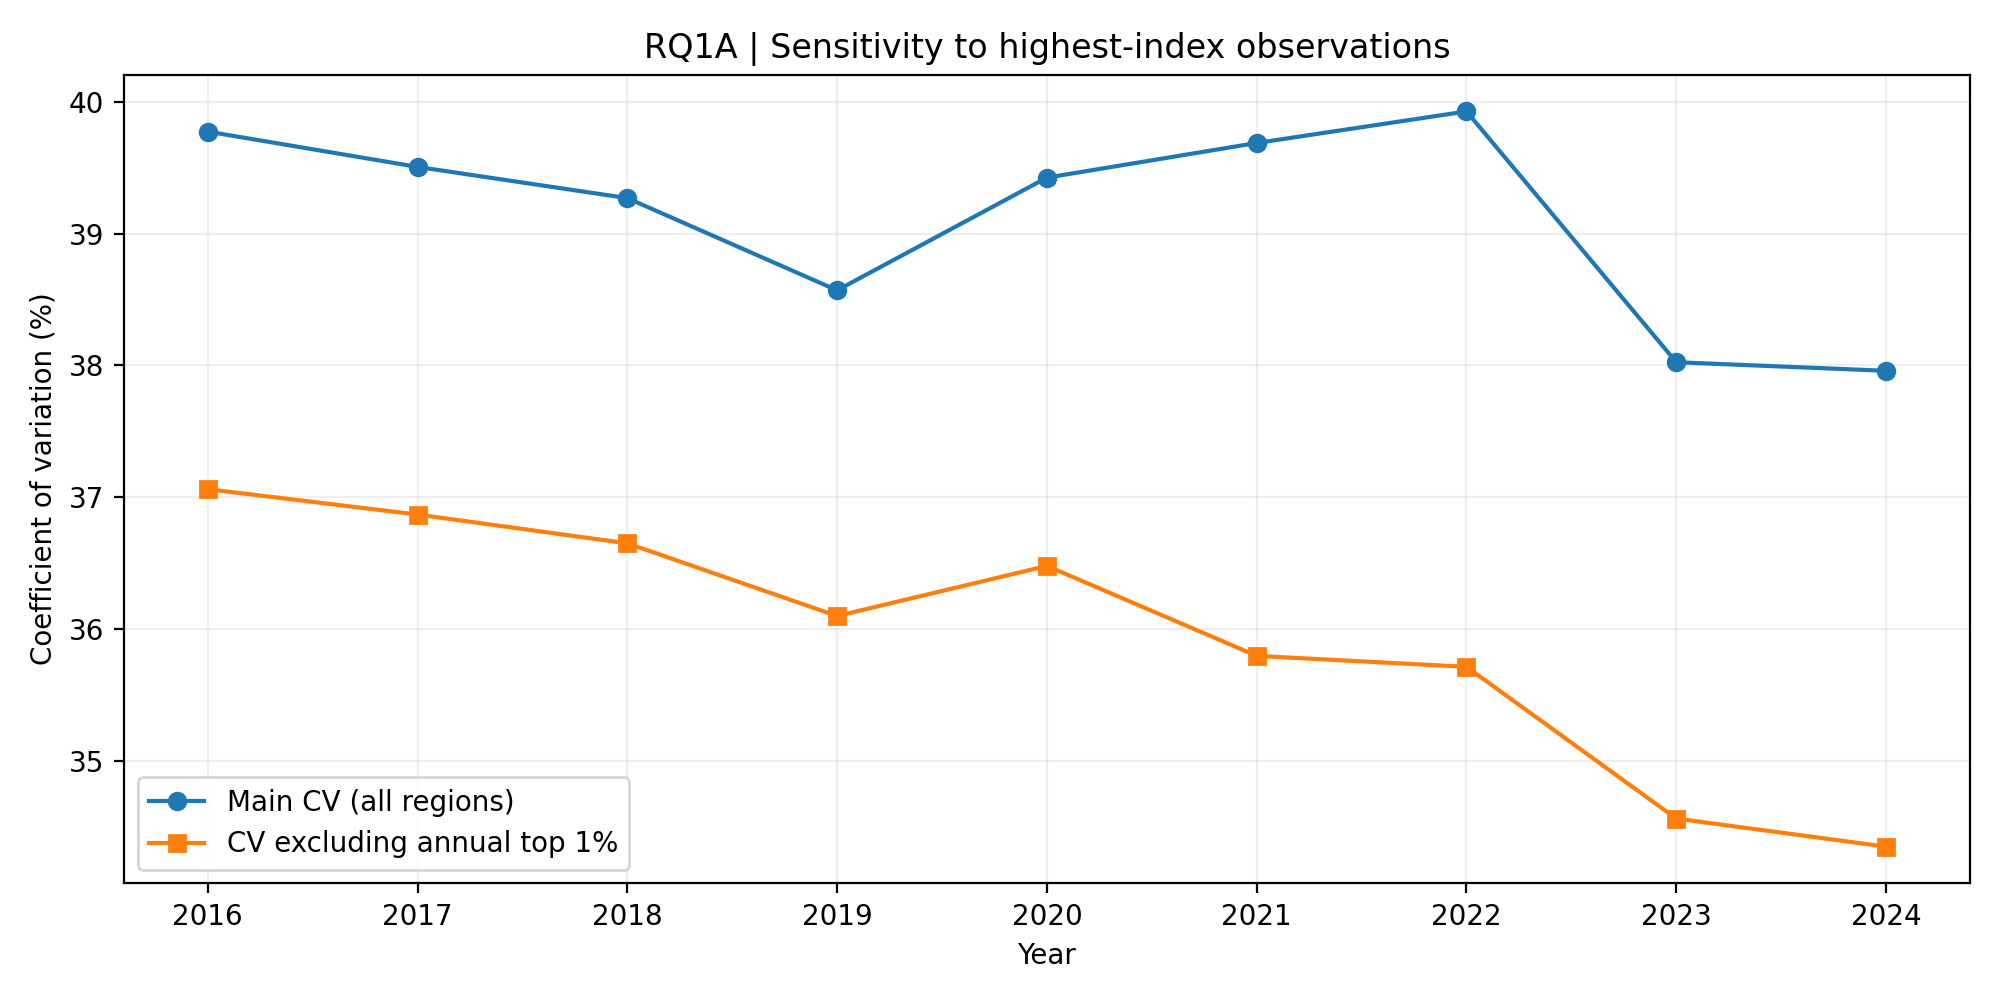

,year,n_regions_main,cv_pct_main,sd_main,p90_p10_gap_main,iqr,n_regions_trim_top_1pct,cv_pct_trim_top_1pct,sd_trim_top_1pct,p90_p10_gap_trim_top_1pct,cv_difference_pp
0,2016,244,39.77,37.56,88.7,48.25,241,37.06,34.37,86.0,-2.71
1,2017,244,39.51,37.25,90.1,47.50,241,36.87,34.14,86.0,-2.64
2,2018,244,39.27,36.98,90.7,47.00,241,36.65,33.89,87.0,-2.62
3,2019,244,38.57,36.23,85.7,46.25,241,36.10,33.33,83.0,-2.47
4,2020,244,39.43,37.15,85.7,45.25,241,36.48,33.72,82.0,-2.95
5,2021,244,39.69,37.35,83.0,44.50,241,35.79,32.97,81.0,-3.89
6,2022,244,39.93,37.67,84.0,44.00,241,35.71,32.95,78.0,-4.22
7,2023,244,38.02,35.81,79.4,41.25,241,34.56,31.91,76.0,-3.46
8,2024,244,37.96,35.69,75.7,39.25,241,34.35,31.65,74.0,-3.61


,year,n_regions_main,cv_pct_main,sd_main,p90_p10_gap_main,iqr,n_regions_trim_top_1pct,cv_pct_trim_top_1pct,sd_trim_top_1pct,p90_p10_gap_trim_top_1pct,cv_difference_pp
0,2016,244,39.77,37.56,88.7,48.25,241,37.06,34.37,86.0,-2.71
1,2017,244,39.51,37.25,90.1,47.50,241,36.87,34.14,86.0,-2.64
2,2018,244,39.27,36.98,90.7,47.00,241,36.65,33.89,87.0,-2.62
3,2019,244,38.57,36.23,85.7,46.25,241,36.10,33.33,83.0,-2.47
4,2020,244,39.43,37.15,85.7,45.25,241,36.48,33.72,82.0,-2.95
5,2021,244,39.69,37.35,83.0,44.50,241,35.79,32.97,81.0,-3.89
6,2022,244,39.93,37.67,84.0,44.00,241,35.71,32.95,78.0,-4.22
7,2023,244,38.02,35.81,79.4,41.25,241,34.56,31.91,76.0,-3.46
8,2024,244,37.96,35.69,75.7,39.25,241,34.35,31.65,74.0,-3.61


,year,n_regions_main,cv_pct_main,sd_main,p90_p10_gap_main,iqr,n_regions_trim_top_1pct,cv_pct_trim_top_1pct,sd_trim_top_1pct,p90_p10_gap_trim_top_1pct,cv_difference_pp
0,2016,244,39.7746,37.5593,88.7,48.25,241,37.0598,34.3672,86.0,-2.7148
1,2017,244,39.5064,37.2478,90.1,47.50,241,36.8671,34.1395,86.0,-2.6394
2,2018,244,39.2697,36.9779,90.7,47.00,241,36.6488,33.8948,87.0,-2.6209
3,2019,244,38.5696,36.2348,85.7,46.25,241,36.0969,33.3260,83.0,-2.4727
4,2020,244,39.4251,37.1501,85.7,45.25,241,36.4773,33.7241,82.0,-2.9478
5,2021,244,39.6881,37.3475,83.0,44.50,241,35.7943,32.9694,81.0,-3.8938
6,2022,244,39.9277,37.6712,84.0,44.00,241,35.7111,32.9535,78.0,-4.2166
7,2023,244,38.0237,35.8092,79.4,41.25,241,34.5591,31.9076,76.0,-3.4646
8,2024,244,37.9585,35.6857,75.7,39.25,241,34.3457,31.6508,74.0,-3.6128


In [4]:
rq1a_out = OUTPUTS / "rq1a"
show_image(rq1a_out / "figure_3_outlier_sensitivity.png")
show_csv(rq1a_out / "outlier_sensitivity.csv", decimals=2)
show_csv(rq1a_out / "outlier_sensitivity.csv", decimals=2)

## 1.2. Are employment gaps narrowing?

Employment convergence is evaluated with the standard deviation, coefficient of variation, and P90 minus P10 gap.

,sample,year,mean,std_dev,coef_variation_pct,p10,p90,p90_minus_p10
0,master,2016,70.00,8.60,12.28,57.38,79.98,22.60
1,master,2017,71.20,8.44,11.85,58.88,80.32,21.44
2,master,2018,72.23,8.39,11.61,60.66,81.48,20.82
3,master,2019,73.16,8.19,11.19,61.76,81.74,19.98
4,master,2020,72.33,8.17,11.30,60.13,80.60,20.47
5,master,2021,73.25,8.06,11.01,61.60,81.98,20.38
6,master,2022,74.86,7.77,10.38,63.60,83.30,19.70
7,master,2023,75.52,7.46,9.88,65.66,83.60,17.94
8,master,2024,75.89,7.41,9.76,66.99,83.57,16.58
9,constant,2016,70.11,8.43,12.03,57.95,80.00,22.05


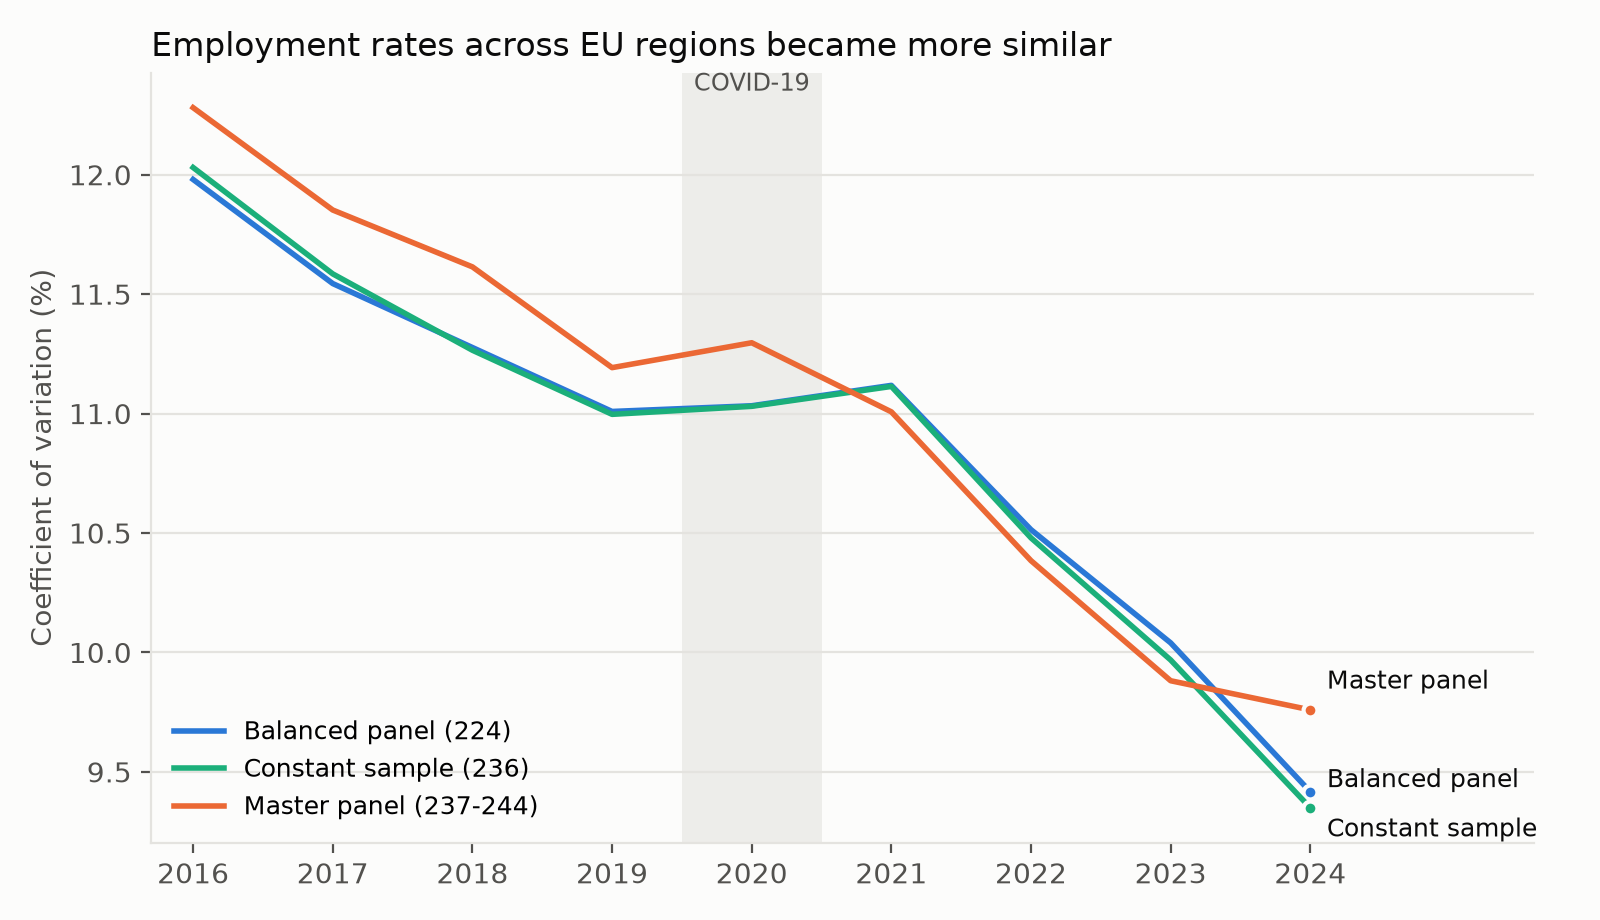

In [5]:
rq1b_out = OUTPUTS / "rq1b"
rq1b_fig = rq1b_out / "figures"
employment_dispersion = show_csv(
    rq1b_out / "rq1b_employment_dispersion_by_year.csv",
    ["sample", "year", "mean", "std_dev", "coef_variation_pct", "p10", "p90", "p90_minus_p10"],
    decimals=2,
)
show_image(rq1b_fig / "fig1_employment_cv_by_year.png")

Employment rates across EU regions became more similar between 2016 and 2024. The coefficient of variation fell in the master, balanced, and constant samples. This means that employment differences between regions became smaller. In the balanced panel, the average employment rate rose from about 69.6% to 75.6%. The standard deviation also fell from 8.34 to 7.12 percentage points. There was a small pause around the COVID-19 period, but the downward trend continued after 2021. The three samples show almost the same pattern. This makes the result more reliable. The findings support Butkus et al. (2026), who found employment catch-up across EU regions. However, the employment gap did not disappear. Some regions still had much lower employment rates than others. Overall, the results provide clear evidence of employment convergence from 2016 to 2024.

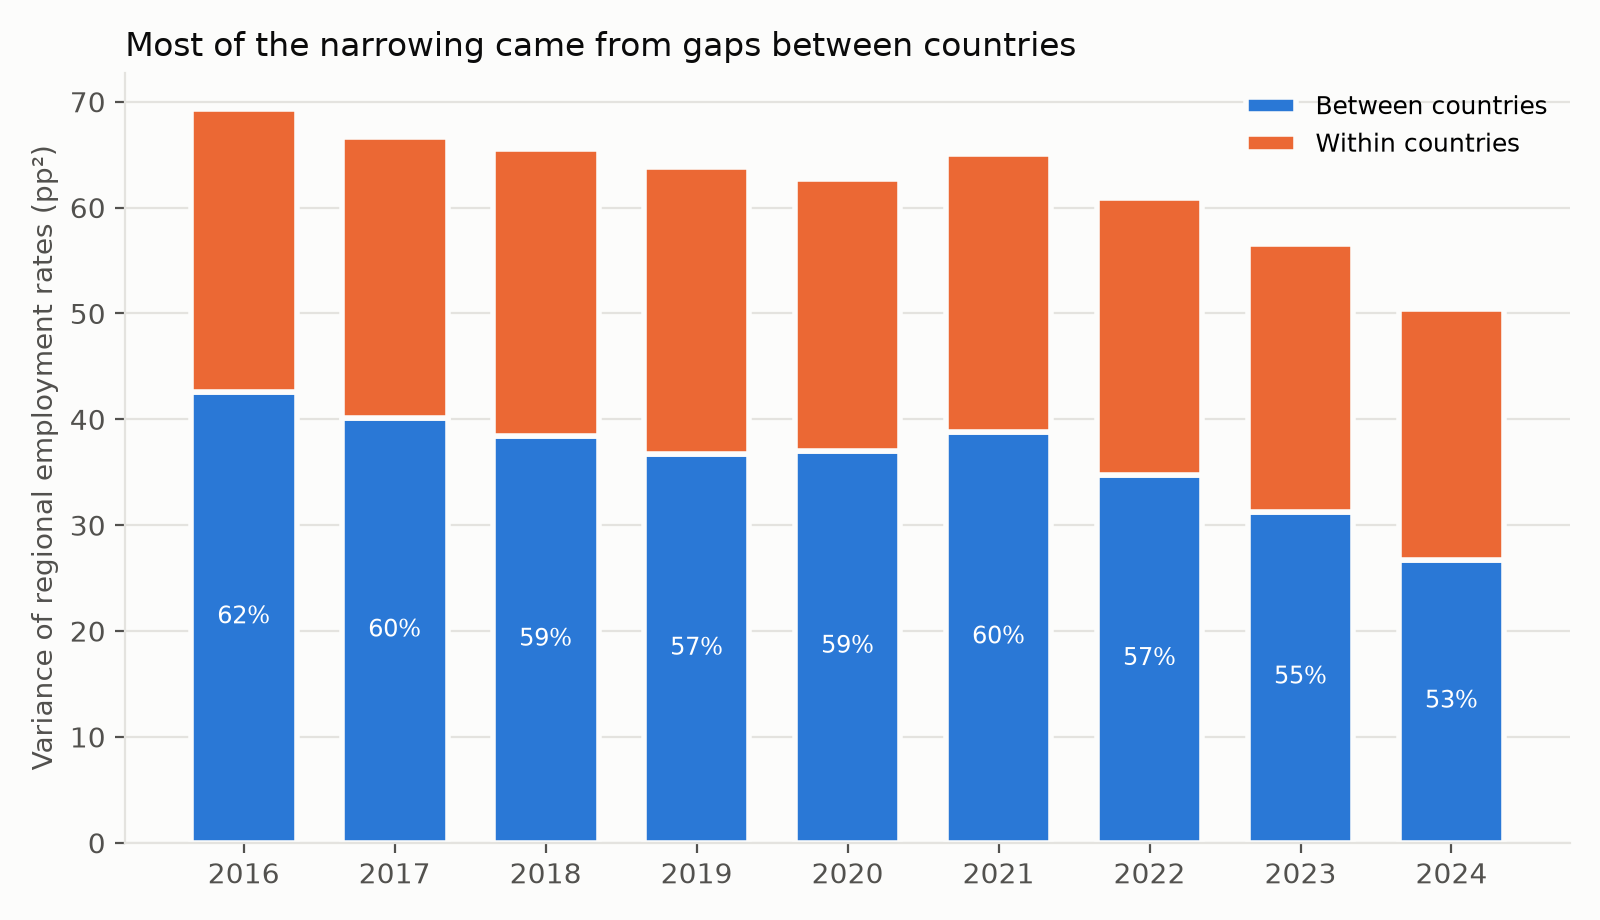

,year,total_variance,between_country_variance,within_country_variance,between_country_share_pct,within_country_share_pct
0,2016,69.282,42.622,26.660,61.520,38.480
1,2017,66.627,40.114,26.513,60.207,39.793
2,2018,65.531,38.381,27.150,58.569,41.431
3,2019,63.812,36.684,27.128,57.487,42.513
4,2020,62.683,37.049,25.634,59.105,40.895
5,2021,65.070,38.815,26.256,59.650,40.350
6,2022,60.865,34.739,26.126,57.076,42.924
7,2023,56.522,31.233,25.289,55.258,44.742
8,2024,50.449,26.679,23.770,52.883,47.117


,year,total_variance,between_country_variance,within_country_variance,between_country_share_pct,within_country_share_pct
0,2016,69.282,42.622,26.660,61.520,38.480
1,2017,66.627,40.114,26.513,60.207,39.793
2,2018,65.531,38.381,27.150,58.569,41.431
3,2019,63.812,36.684,27.128,57.487,42.513
4,2020,62.683,37.049,25.634,59.105,40.895
5,2021,65.070,38.815,26.256,59.650,40.350
6,2022,60.865,34.739,26.126,57.076,42.924
7,2023,56.522,31.233,25.289,55.258,44.742
8,2024,50.449,26.679,23.770,52.883,47.117


In [6]:
show_image(rq1b_fig / "fig3_between_within_country_variance.png")
show_csv(rq1b_out / "rq1b_between_within_country.csv", decimals=3)

The chart shows that regional employment differences became smaller from 2016 to 2024. Total variation fell from about 69 to 50 percentage points squared. Most of this decline came from smaller differences between countries. Between-country variation fell from about 43 in 2016 to 27 in 2024. Its share of total variation also fell from about 62% to 53%. Differences within countries fell more slowly. Their share therefore increased from about 38% to 47%. There was a small increase in total variation in 2021, but the decline continued after that year. These results show that employment convergence was stronger between EU countries than within individual countries. This agrees with studies showing that EU regions can move closer overall while large differences remain inside countries. EU policy should therefore focus not only on poorer countries, but also on weaker regions within each country.

# 2. BETA CONVERGENCE
Beta convergence tests whether regions with lower starting GDP grew faster than regions with higher starting GDP.

## 2.1. Do poorer EU regions grow faster?

The preferred model regresses annualised log GDP growth from 2016 to 2024 on log GDP in 2016. Standard errors are clustered by country because regions within the same country may experience common shocks.

,model,n_regions,slope,se_cluster,p_value,r_squared,speed,half_life_yrs
0,A. Full sample,244,-0.0167,0.0045,0.0002,0.2371,0.0179,38.7851
1,B. Excl. commuter ring,237,-0.0168,0.0045,0.0002,0.2412,0.0180,38.4473
2,B2. Excl. core + ring,230,-0.0191,0.0043,0.0000,0.3002,0.0207,33.4276
3,C. Excl. break-flag regions,223,-0.0152,0.0051,0.0028,0.1937,0.0162,42.7837
4,D. Excl. influential regions,228,-0.0182,0.0032,0.0000,0.3691,0.0196,35.3119
5,E. End year 2023,244,-0.0167,0.0047,0.0004,0.2206,0.0177,39.1028
6,F. Excl. Ireland,241,-0.0183,0.0042,0.0000,0.2888,0.0198,34.9830
7,G. Excl. French overseas,239,-0.0176,0.0046,0.0001,0.2615,0.0189,36.5790
8,H. Excl. Ireland + overseas,236,-0.0193,0.0042,0.0000,0.3181,0.0210,32.9995
9,I. Excl. team outlier list,240,-0.0187,0.0043,0.0000,0.2820,0.0202,34.2836


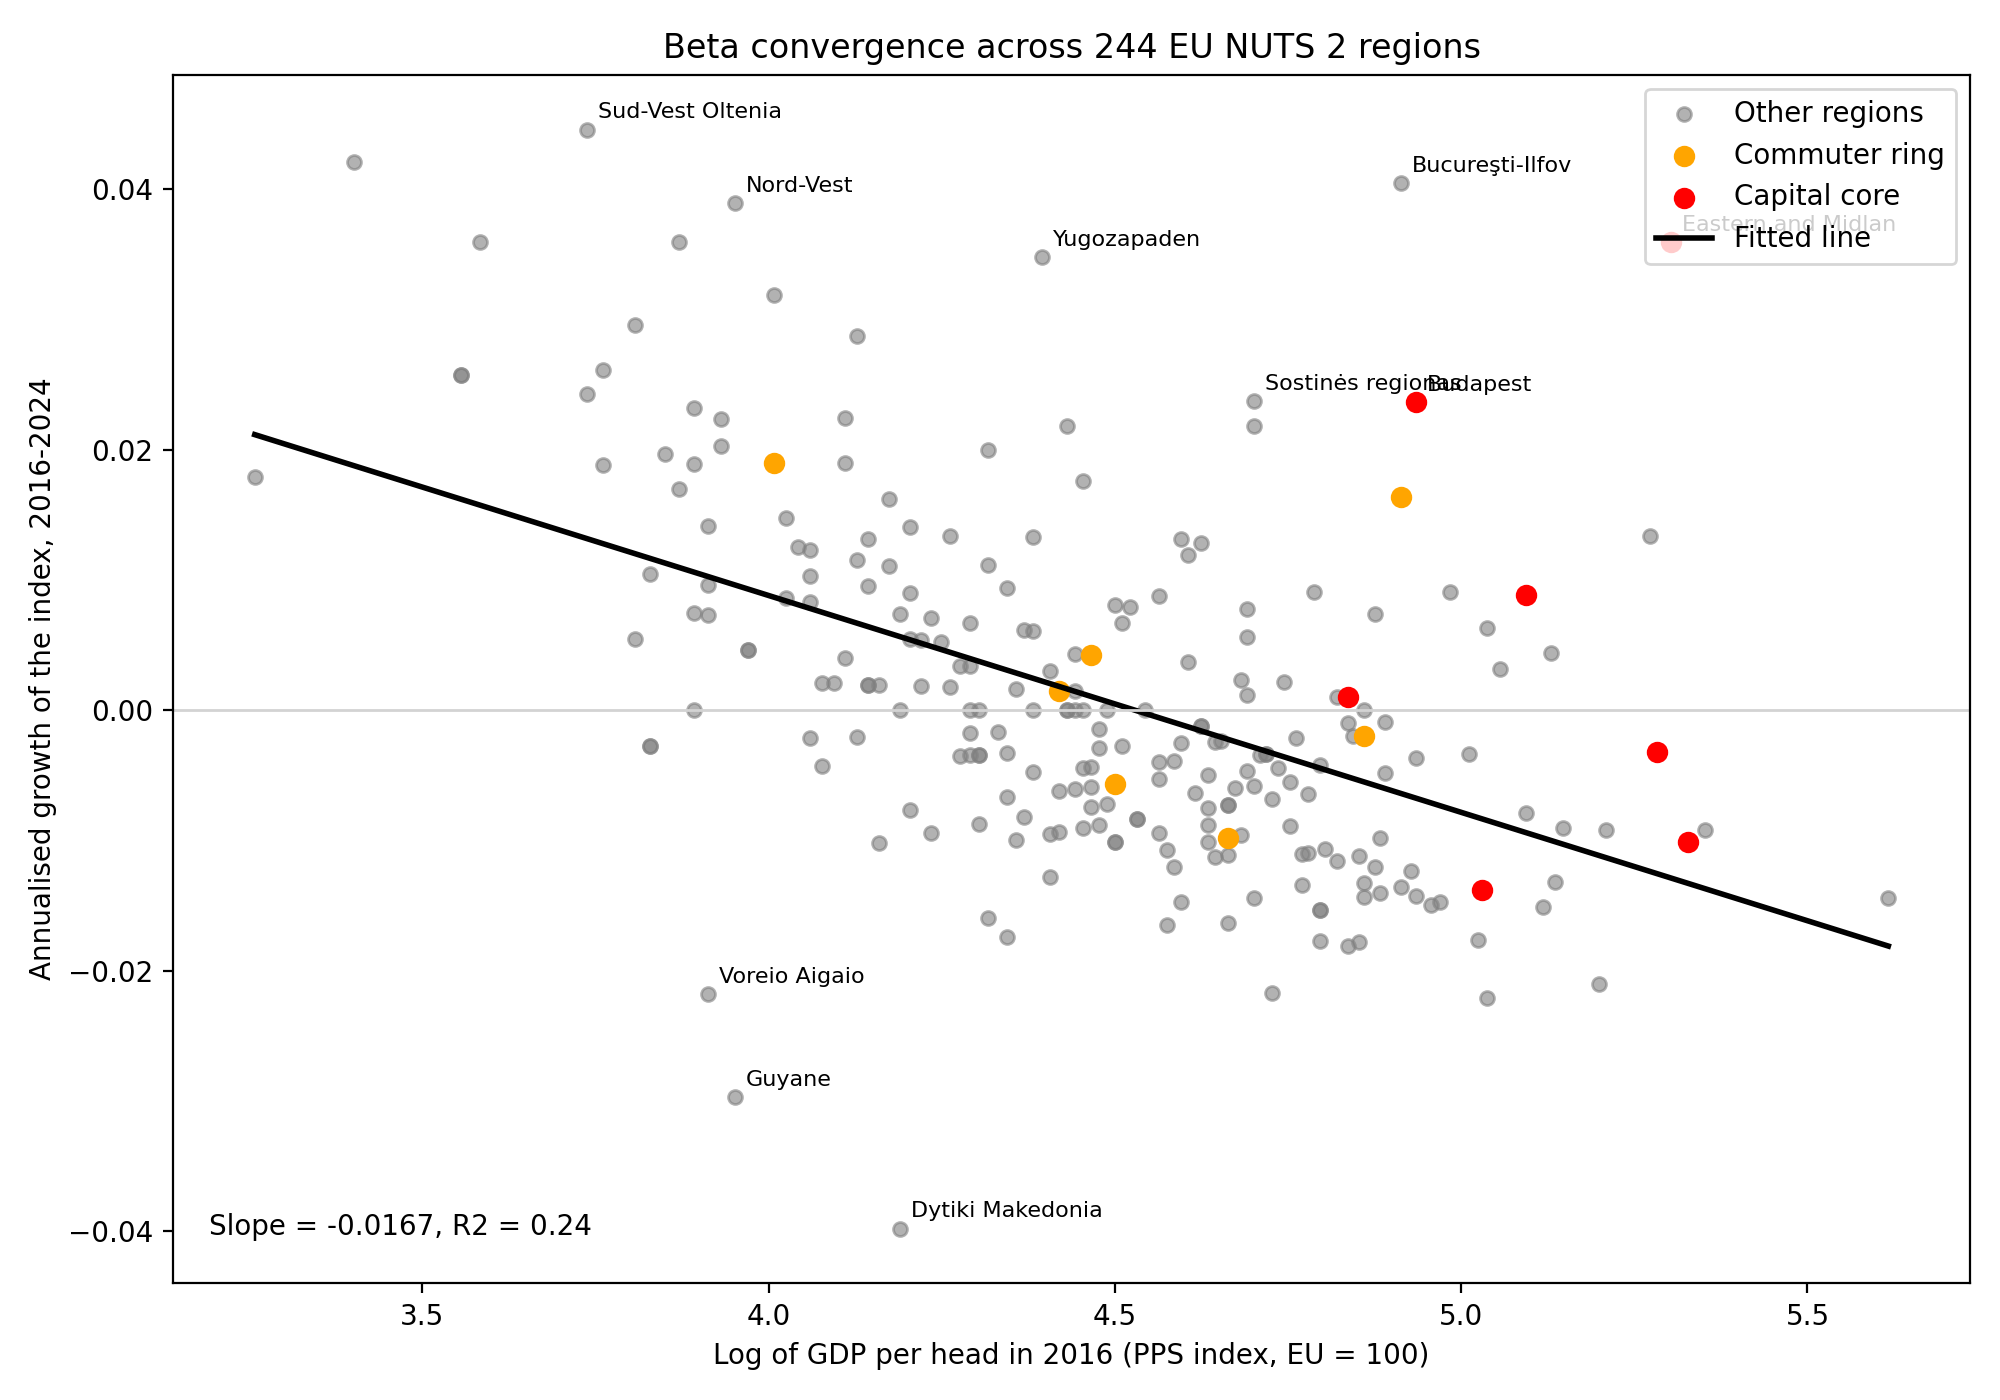

In [7]:
rq2_out = OUTPUTS
rq2_results = show_csv(rq2_out / "rq2_results.csv", decimals=4)
show_image(rq2_out / "rq2_plot1_scatter.png")

The graph shows that poorer EU regions generally grew faster than richer regions between 2016 and 2024. This can be seen from the downward fitted line. The slope is -0.0167, which supports beta convergence. However, the R² value is only 0.24. This means that starting GDP explains 24% of the differences in growth. Other factors were also important. Some poorer regions grew strongly, while others had little or negative growth. Some richer regions also continued to grow. Capital and commuter regions did not follow one clear pattern. This supports earlier studies showing that regional convergence is slow and uneven. Overall, the result answers the second research question positively. Poorer regions grew faster on average, but many regional differences remain.

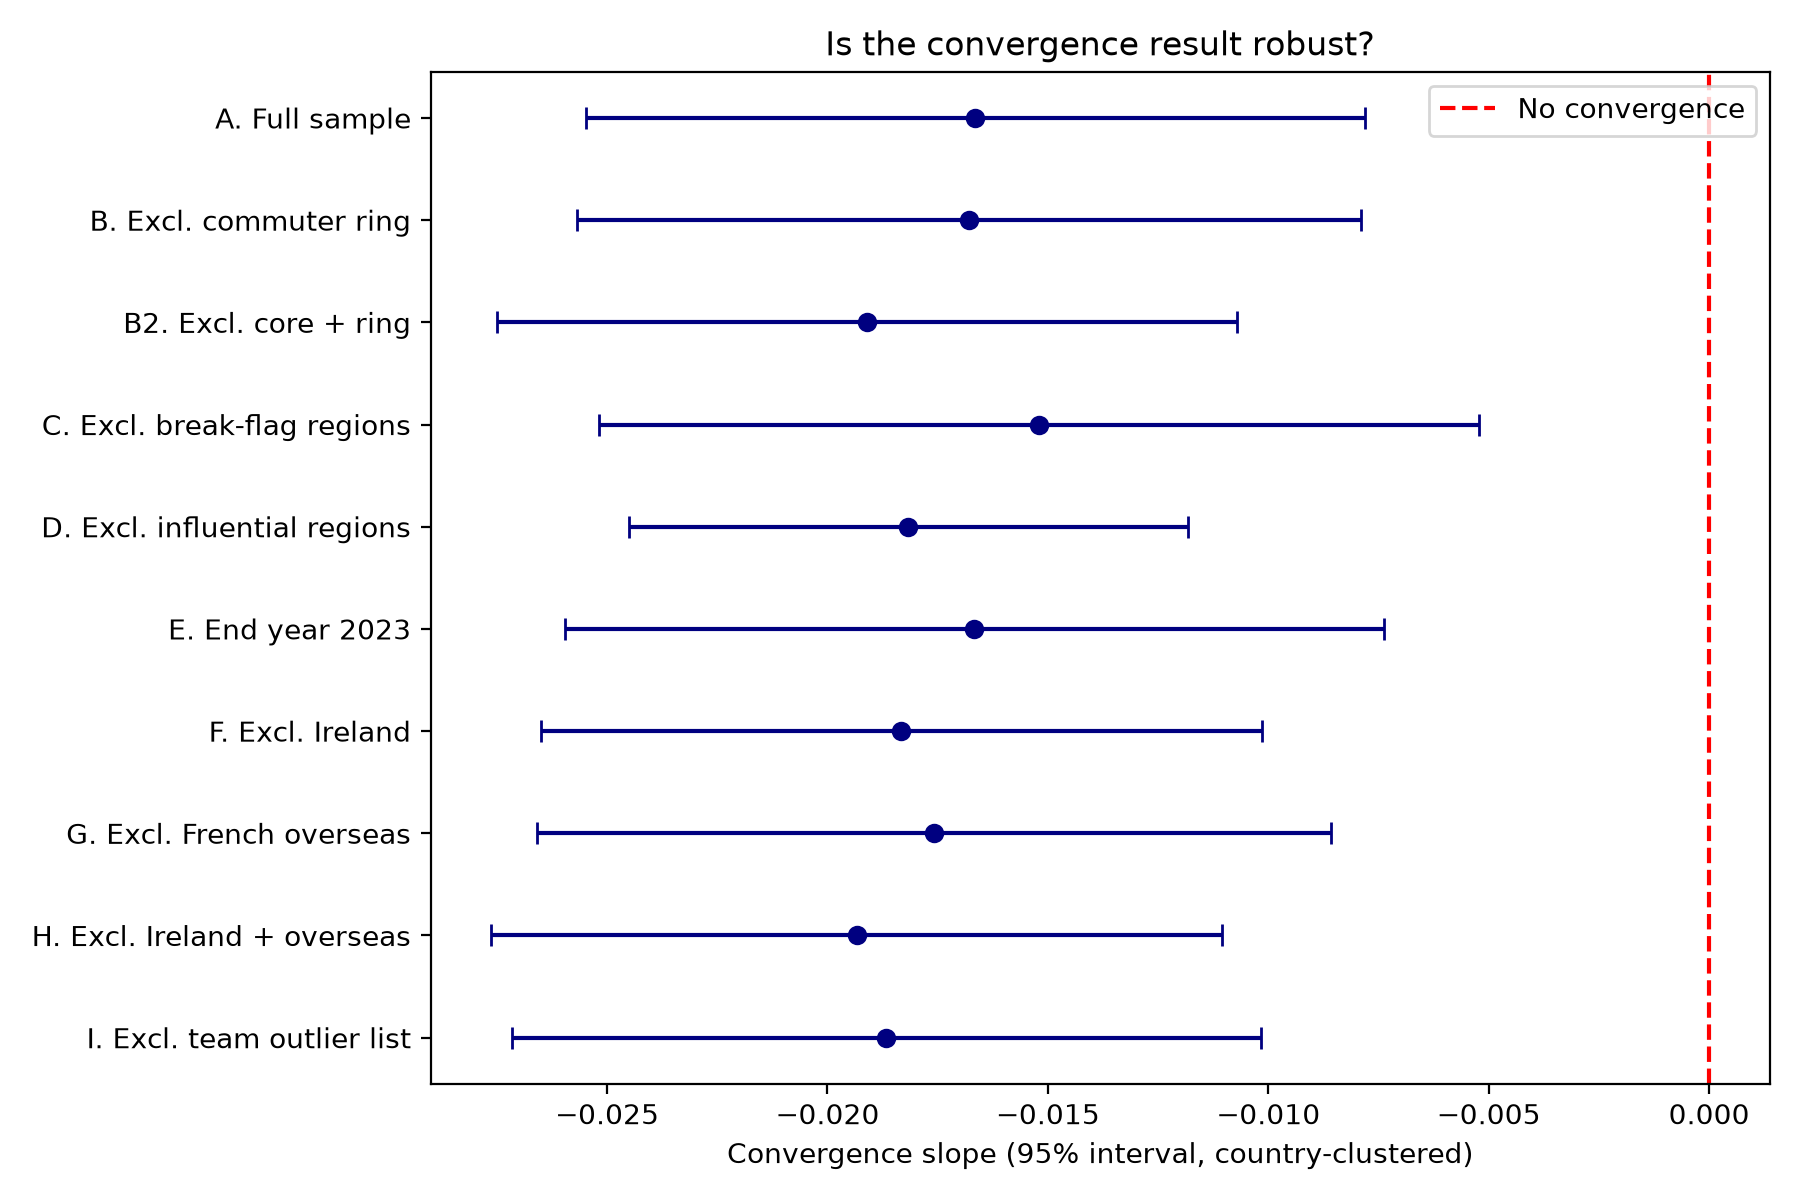

In [8]:
show_image(rq2_out / "rq2_plot2_robustness.png")

The graph shows that the beta convergence result is robust. The estimated slope remains negative in every test. The 95% confidence intervals also remain below the red zero line. This means that the evidence of convergence does not depend on one group of unusual regions. The same result remains after removing commuter regions, capital regions, break-flag observations, influential regions, Ireland, French overseas regions, and the team’s outlier list. The slope changes slightly across the tests, but the main conclusion does not change. Poorer regions still grew faster than richer regions on average. The strongest negative slope appears when capital cores and commuter rings are removed. Overall, the analysis provides reliable evidence of beta convergence across EU regions between 2016 and 2024.

# 3. REGIONAL PROFILES AND CLUSTERING 

## 3.1. Which regions behave alike?

This analysis groups EU NUTS 2 regions that show similar economic and employment patterns. Six measures are used to create the groups. These are the average GDP level, change in GDP, average employment rate, change in employment, average unemployment rate, and change in unemployment. The measures show both the general position of each region and how the region changed over time. Before grouping the regions, all six measures are put on the same scale. This prevents a measure with larger numbers from having too much influence on the results. The final groups therefore reflect the combined GDP, employment, and unemployment patterns of the regions.

### 3.3.1 Method

The analysis uses K-means clustering to place similar regions into groups. The model is run 50 times with a fixed random seed of 42. This helps to produce a stable result. Different solutions with two to eight groups are tested. The elbow method and silhouette score are used to choose the best number of groups. Three groups are selected. The result is checked using Ward hierarchical clustering and repeated tests with 80% of the regions. Principal component analysis is then used to show the regional groups on a simple two-dimensional graph. The first component explains 53% of the differences between regions, while the second explains 23%. Together, the two components show 76% of the total differences in the regional profiles.

In [9]:
from pathlib import Path
from runpy import run_path

# The notebook is inside the notebooks folder
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

SRC = ROOT / "src"
OUTPUTS = ROOT / "outputs"

rq3_script = SRC / "rq3_clusters.py"
rq3_out = OUTPUTS / "rq3"

print("Project root:", ROOT)
print("RQ3 script:", rq3_script)
print("Script exists:", rq3_script.exists())

if rq3_script.exists():
    try:
        run_path(str(rq3_script), run_name="__main__")
        print("RQ3 analysis completed.")
    except Exception as exc:
        print(f"RQ3 analysis failed: {type(exc).__name__}: {exc}")
else:
    print(f"RQ3 script not found: {rq3_script}")

Project root: /Users/felix/EU_Regional_Convergence_Project
RQ3 script: /Users/felix/EU_Regional_Convergence_Project/src/rq3_clusters.py
Script exists: True


 k  inertia  silhouette
 2  874.413       0.369
 3  632.803       0.351
 4  538.279       0.260
 5  474.585       0.264
 6  421.492       0.273
 7  381.396       0.283
 8  347.296       0.250

Using k = 3
k-means vs Ward (ARI): 0.88
stability over 100 random 80% subsamples (mean ARI): 0.95

          gdp_level_log  gdp_rel_growth  emp_level  emp_change  unemp_level  unemp_change  n_regions  gdp_level_(index)
cluster                                                                                                               
1                 4.68           -0.49      76.45        4.19         5.72         -1.81        131             107.45
2                 4.20            1.90      72.91        8.28         5.43         -3.17         55              66.75
3                 4.14           -0.21      59.80        8.72        16.51         -9.18         38              63.05

GEOGRAPHY: cluster vs country ARI=0.11, NMI=0.37
countries with 2+ regions that end up in 2+ clusters: 9 of 22


### 3.2. Choosing the number of clusters

,k,inertia,silhouette
0,2,874.413,0.369
1,3,632.803,0.351
2,4,538.279,0.260
3,5,474.585,0.264
4,6,421.492,0.273
5,7,381.396,0.283
6,8,347.296,0.250


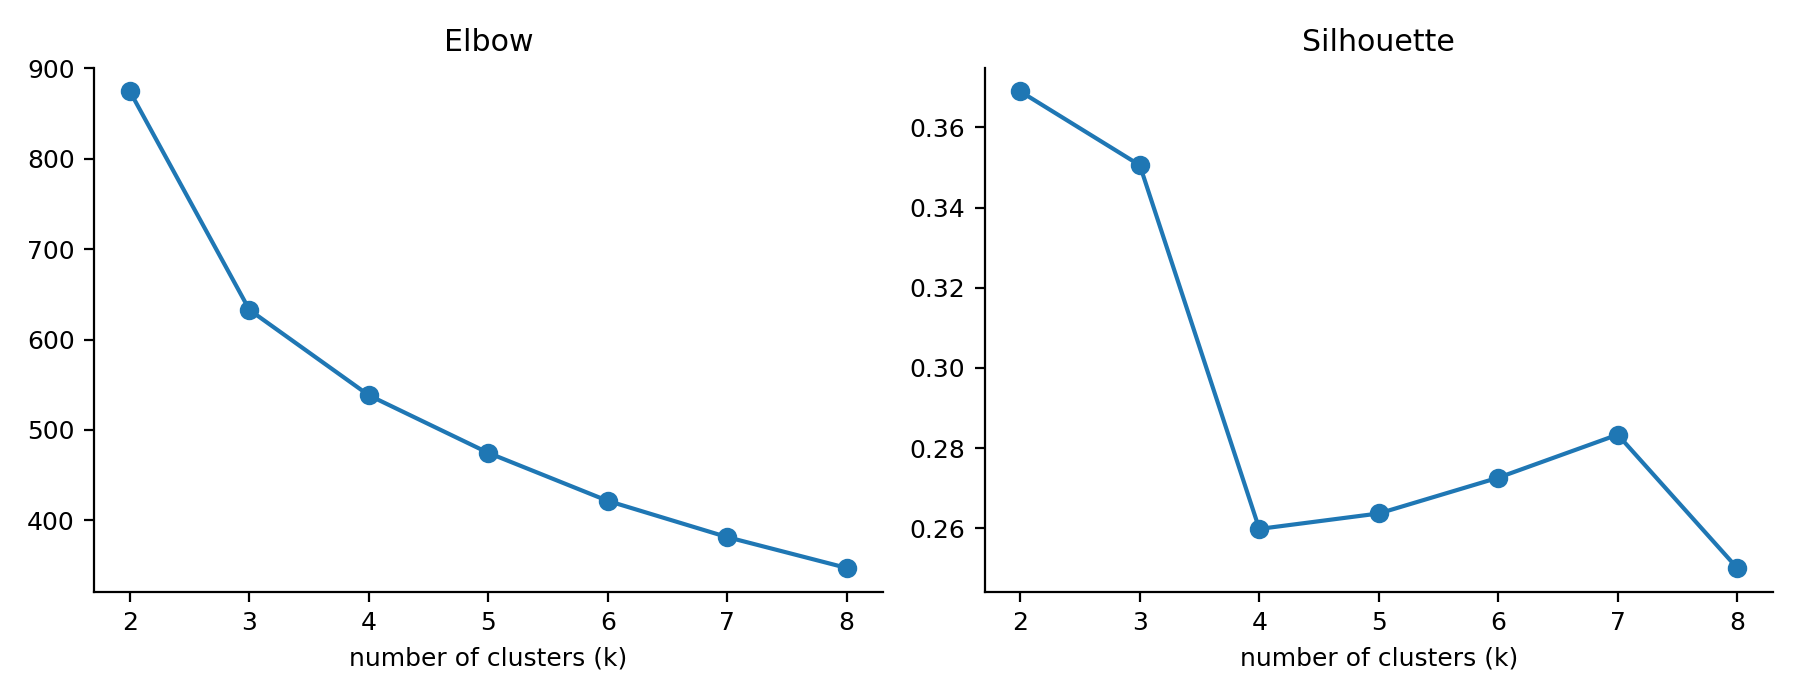

In [10]:
import pandas as pd
from IPython.display import display, Image

choose_k_path = rq3_out / "rq3_choose_k.csv"

if choose_k_path.exists():
    display(pd.read_csv(choose_k_path).round(3))
else:
    print(f"Table not found: {choose_k_path}. Run the RQ3 pipeline first.")

figure_path = rq3_out / "rq3_fig1_choose_k.png"
if figure_path.exists():
    display(Image(filename=str(figure_path), width=1000))
else:
    print(f"Visual not found: {figure_path}. Run the RQ3 pipeline first.")

Two clusters had the highest silhouette score of 0.37, while three clusters scored 0.35. The difference is small. The elbow result also shows a strong improvement from two to three clusters. After three clusters, the improvement becomes much smaller. Three clusters were therefore chosen because they provide more detail about the regional groups without losing much separation. The result is stable because K-means and Ward clustering produced similar groups, with an agreement score of 0.88. Repeated tests using 80% of the regions gave a stability score of 0.95. This shows that the three-cluster solution is reliable and suitable for explaining the different regional profiles. The elbow graph shows a strong improvement when the number of clusters increases from two to three. After three clusters, the improvement becomes smaller. The silhouette score is highest for two clusters at 0.369. Three clusters have a slightly lower score of 0.351. However, this difference is small. Solutions with four to eight clusters have much lower scores, ranging from 0.250 to 0.283. Three clusters were therefore selected because they still separate the regions well and provide more useful detail than two broad groups. The results show that three clusters offer a good balance between clear separation and meaningful regional profiles.

### 3.3. Regional clusters in the PCA space

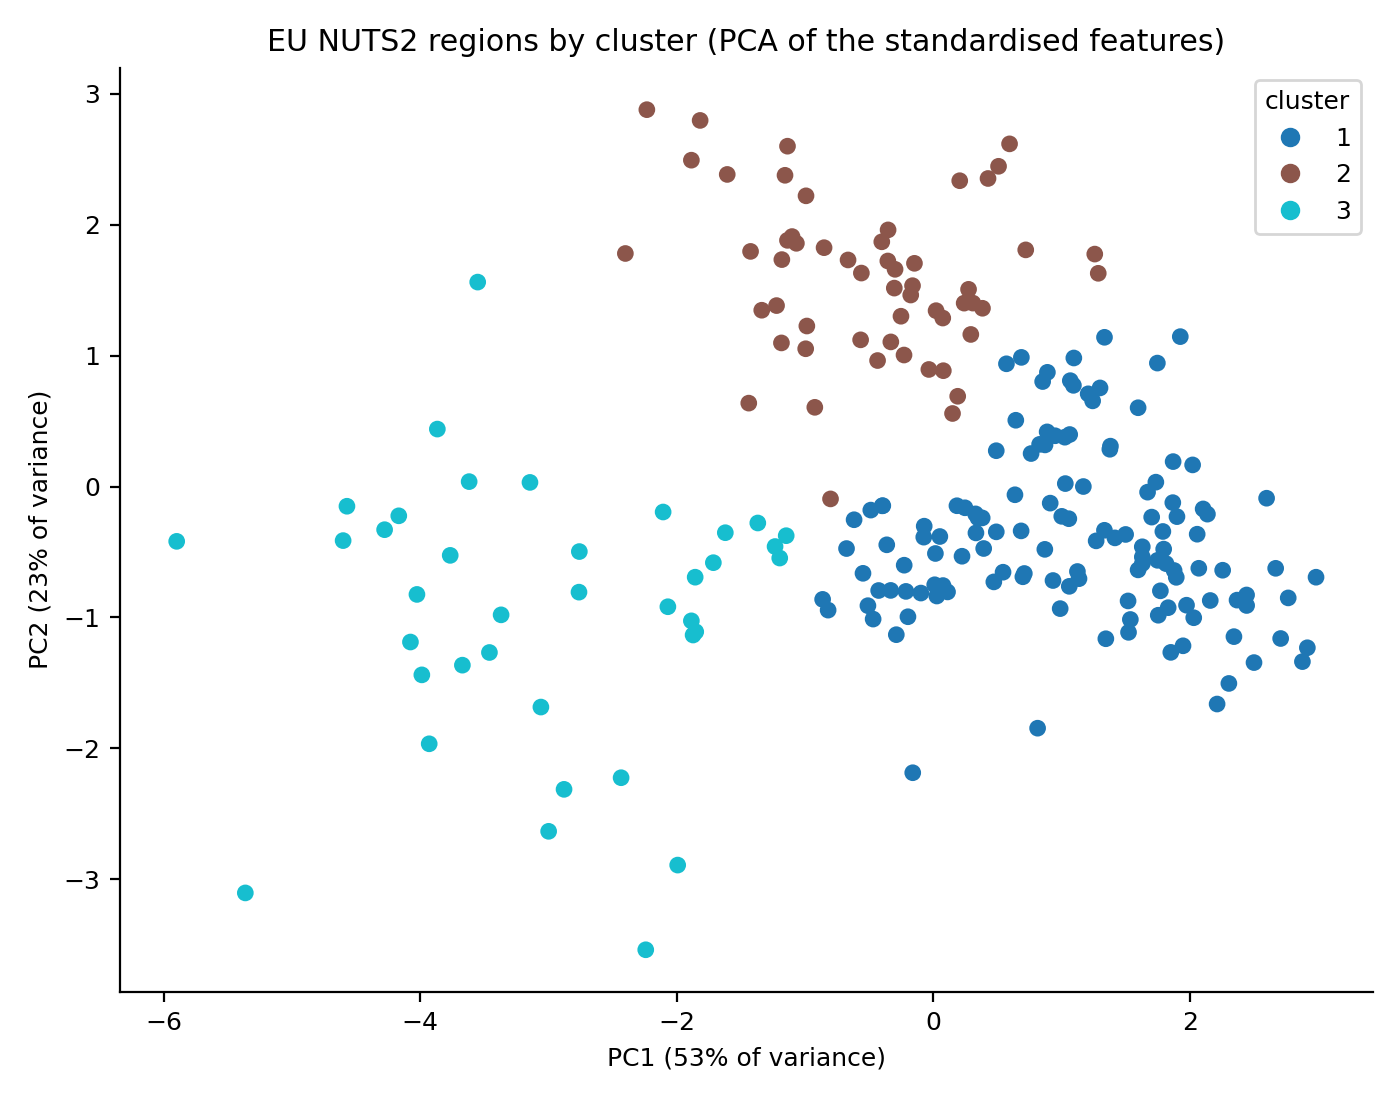

In [11]:
from IPython.display import display, Image

pca_figure = rq3_out / "rq3_fig2_clusters_pca.png"
if pca_figure.exists():
    display(Image(filename=str(pca_figure), width=900))
else:
    print(f"Visual not found: {pca_figure}. Run the RQ3 pipeline first.")

The PCA graph shows three groups of EU regions. Cluster 3 is the clearest group because it is separated from most of the other regions. Cluster 2 is mainly found in the upper part of the graph. Cluster 1 is the largest group and is mainly found on the right side. Some regions from the different groups are close together near the centre. This means that the groups are not completely separate. The graph still shows clear differences in the economic and employment patterns of the regions. Overall, EU regions can be placed into three useful groups, but some regions share similar features.

### 3.4. Cluster profiles and geographical interpretation

In [12]:
profiles_path = rq3_out / "rq3_cluster_profiles.csv"
if profiles_path.exists():
    profiles = pd.read_csv(profiles_path, index_col=0)
    display(profiles.round(2))
else:
    print(f"Table not found: {profiles_path}. Run the RQ3 pipeline first.")

country_clusters_path = rq3_out / "rq3_cluster_by_country.csv"
if country_clusters_path.exists():
    country_clusters = pd.read_csv(country_clusters_path, index_col=0)
    display(country_clusters.round(0))
else:
    print(f"Table not found: {country_clusters_path}. Run the RQ3 pipeline first.")

eta_squared_path = rq3_out / "rq3_country_eta_squared.csv"
if eta_squared_path.exists():
    display(pd.read_csv(eta_squared_path, index_col=0).round(2))
else:
    print(f"Table not found: {eta_squared_path}. Run the RQ3 pipeline first.")

,gdp_level_log,gdp_rel_growth,emp_level,emp_change,unemp_level,unemp_change,n_regions,gdp_level_(index)
cluster,,,,,,,,
1,4.68,-0.49,76.45,4.19,5.72,-1.81,131,107.45
2,4.20,1.90,72.91,8.28,5.43,-3.17,55,66.75
3,4.14,-0.21,59.80,8.72,16.51,-9.18,38,63.05


,1,2,3
country_code,,,
AT,9,0,0
BE,11,0,0
BG,0,6,0
CY,0,1,0
CZ,8,0,0
DE,28,0,0
DK,5,0,0
EE,1,0,0
EL,0,0,13


,share_explained_by_country
gdp_level_log,0.51
gdp_rel_growth,0.77
emp_level,0.58
emp_change,0.69
unemp_level,0.67
unemp_change,0.72


The analysis found three main groups of EU regions. Cluster 1 is the largest, with 131 regions. These regions have the highest GDP and employment levels and low unemployment. Cluster 2 has 55 regions. These regions have lower GDP but show the strongest GDP growth. This group shows the clearest catch-up pattern. Cluster 3 has 38 regions. These regions have the lowest employment and the highest unemployment, although their labour results improved. Country location explains an important part of these differences. It explains 51% of GDP levels, 77% of GDP growth, and 58% of employment levels. It also explains 69% of employment change, 67% of unemployment levels, and 72% of unemployment change. However, some countries have regions in different clusters. This shows that geography matters, but differences within countries also matter. Industrial structure cannot be fully tested because sector data were not included.

# 4. CONNECTING SIGMA AND BETA CONVERGENCE

## 4.1. Where do the two tests agree or disagree?

Beta convergence and sigma convergence answer related but different questions. Poor regions can grow faster on average while new shocks temporarily increase the overall spread.

,start,end,pct_change,trend_per_year,years_rising
sd_log,0.3949,0.3551,-10.0880,-0.0047,1
cv,0.3977,0.3796,-4.5658,-0.0015,3
p90_p10,2.7634,2.3281,-15.7540,-0.0559,1
sd_log_excl_outliers,0.3797,0.3355,-11.6597,-0.0054,1
cv_excl_outliers,0.3675,0.3387,-7.8222,-0.0034,1


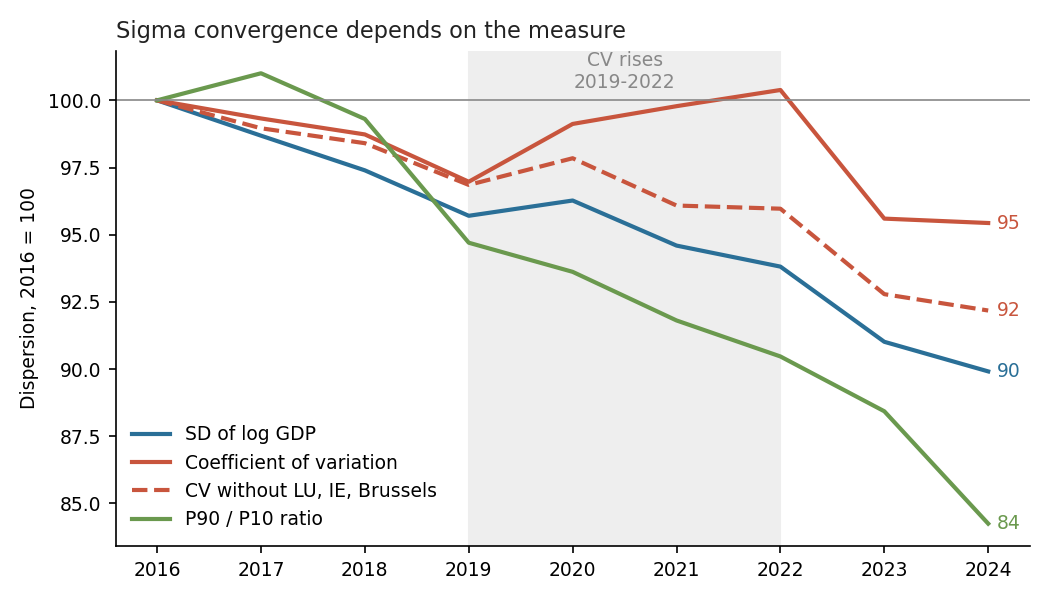

In [13]:
rq4_out = OUTPUTS / "rq4"

summary_path = rq4_out / "rq4_sigma_trend_summary.csv"
if summary_path.exists():
	display(pd.read_csv(summary_path, index_col=0).round(4))
else:
	print(f"Table not found: {summary_path}")

figure_path = rq4_out / "fig1_sigma_measures.png"
if figure_path.exists():
	display(Image(filename=str(figure_path)))
else:
	print(f"Visual not found: {figure_path}")

The results show that GDP differences between EU regions became smaller from 2016 to 2024. The standard deviation of log GDP fell by about 10%. The gap between the richer and poorer groups fell by about 16%. This gives strong evidence of sigma convergence. The coefficient of variation fell by only about 5%. It also increased between 2019 and 2022. However, when Luxembourg, Ireland, and Brussels were removed, the decline was stronger at about 8%. This shows that a few very rich regions affected the result. The findings agree with Leško et al. (2026) and Kostadinović and Stanković (2025), who found that EU convergence is real but uneven. Overall, regional GDP gaps became smaller, but the result depends partly on the measure used and the inclusion of unusual high-income regions.

,period,beta,beta_significant_5pct,change_sd_log,change_cv,beta_says,sd_log_says,cv_says,agree_sd_log,agree_cv
0,2016-2017,-0.0151,True,-0.0052,-0.0027,converging,converging,converging,True,True
1,2017-2018,-0.0149,True,-0.0051,-0.0024,converging,converging,converging,True,True
2,2018-2019,-0.0192,True,-0.0067,-0.0070,converging,converging,converging,True,True
3,2019-2020,-0.0041,False,0.0022,0.0086,converging,diverging,diverging,False,False
4,2020-2021,-0.0223,True,-0.0066,0.0026,converging,converging,diverging,True,False
5,2021-2022,-0.0151,False,-0.0031,0.0024,converging,converging,diverging,True,False
6,2022-2023,-0.0350,True,-0.0111,-0.0190,converging,converging,converging,True,True
7,2023-2024,-0.0136,True,-0.0044,-0.0006,converging,converging,converging,True,True


,period,sample,var_start,var_end,change,catch_up_effect,shock_effect,check_sum
0,2016-2024,all,0.1553,0.1256,-0.0298,-0.0386,0.0089,-0.0298
1,2016-2024,excl. outliers,0.1436,0.1121,-0.0315,-0.0397,0.0082,-0.0315
2,2016-2017,all,0.1553,0.1513,-0.0041,-0.0047,0.0006,-0.0041
3,2017-2018,all,0.1513,0.1473,-0.0039,-0.0045,0.0005,-0.0039
4,2018-2019,all,0.1473,0.1423,-0.0051,-0.0056,0.0005,-0.0051
5,2019-2020,all,0.1423,0.1440,0.0017,-0.0012,0.0029,0.0017
6,2020-2021,all,0.1440,0.1390,-0.0050,-0.0064,0.0014,-0.0050
7,2021-2022,all,0.1390,0.1367,-0.0023,-0.0042,0.0019,-0.0023
8,2022-2023,all,0.1367,0.1287,-0.0080,-0.0094,0.0014,-0.0080
9,2023-2024,all,0.1287,0.1256,-0.0031,-0.0035,0.0004,-0.0031


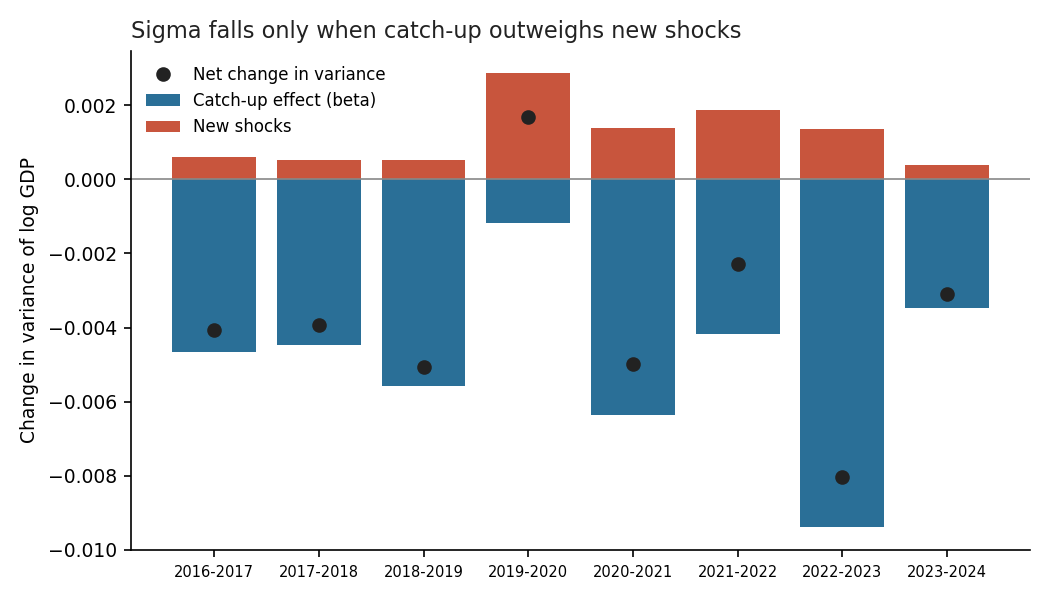

In [14]:
annual_agreement = pd.read_csv(rq4_out / "rq4_annual_agreement.csv")
display(annual_agreement.round(4))

variance_decomposition = pd.read_csv(rq4_out / "rq4_variance_decomposition.csv")
display(variance_decomposition.round(4))

figure = rq4_out / "fig3_variance_decomposition.png"
if figure.exists():
    display(Image(filename=str(figure), width=900))
else:
    print(f"Visual not found: {figure}")

The two tests give a similar result for the full period from 2016 to 2024. Beta convergence shows that poorer regions generally grew faster than richer regions. Sigma convergence also shows that the overall GDP gap became smaller. However, the tests did not agree in every year. The clearest disagreement happened between 2019 and 2020. The beta result was negative, which suggested catch-up, but the result was weak and not statistically significant. At the same time, both sigma measures increased. This means that poorer regions showed some catch-up, but the total gap between regions still became larger. There was also a mixed result from 2020 to 2022. The standard deviation of log GDP fell, while the coefficient of variation increased. This shows that the conclusion can change depending on the measure used. New economic shocks were strong enough to reduce the effect of catch-up during these years. From 2022 to 2024, the tests agreed again. Poorer regions grew faster, and the overall regional gap became smaller. The strongest decline happened between 2022 and 2023. These results support Leško et al. (2026) and Truglia and Zeli (2025), who found that European convergence is uneven and can be affected by temporary shocks. Sigma convergence gives the clearest answer about whether the actual gap became smaller. Beta convergence helps explain whether poorer regions were catching up.

## 4.2. Where is convergence happening?

,total,between_countries,within_countries,share_within
year,,,,
2016,0.1553,0.0861,0.0692,0.4454
2017,0.1513,0.0830,0.0682,0.4510
2018,0.1473,0.0785,0.0689,0.4675
2019,0.1423,0.0727,0.0696,0.4892
2020,0.1440,0.0787,0.0652,0.4532
2021,0.1390,0.0738,0.0652,0.4689
2022,0.1367,0.0702,0.0665,0.4867
2023,0.1287,0.0623,0.0664,0.5160
2024,0.1256,0.0592,0.0664,0.5288


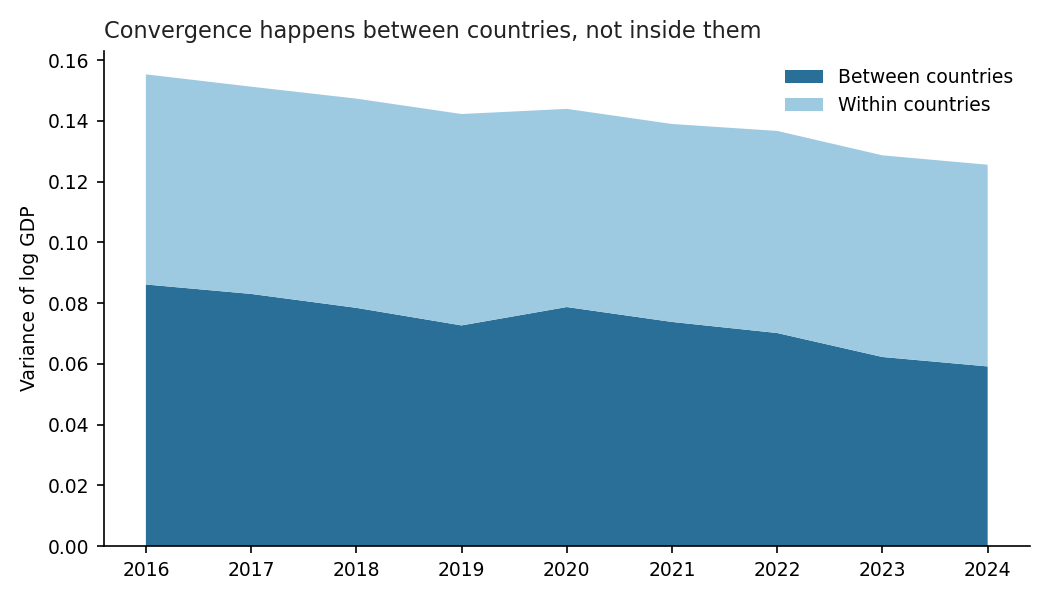

In [15]:
from IPython.display import Image, display
from pathlib import Path

between_within_path = rq4_out / "rq4_between_within.csv"
if between_within_path.exists():
    display(pd.read_csv(between_within_path, index_col=0).round(4))
else:
    print(f"Table not found: {between_within_path}")
figure_path = rq4_out / "fig4_between_within.png"
if figure_path.exists():
    display(Image(filename=str(figure_path), width=900))
else:
    print(f"Visual not found: {figure_path}")
# No additional display call is needed.

The results show that regional GDP differences became smaller between 2016 and 2024. However, most of this change happened between countries. The GDP difference between countries fell from 0.086 in 2016 to 0.059 in 2024. This is a decline of about 31%. It means that poorer EU countries moved closer to richer EU countries. The differences between regions within the same country changed much less. Within-country inequality fell from 0.069 to 0.066. This is a decline of only about 4%. As a result, the share of inequality found within countries increased from about 45% in 2016 to 53% in 2024. There was also a small rise in between-country inequality in 2020. This may be linked to the different effects of the COVID-19 shock. The findings show that EU convergence was mainly driven by countries catching up with one another. However, large differences still remain between regions inside the same country. This agrees with Cieślik and Misiak (2025), who found that national growth does not always reduce all regional gaps. It also supports Leško et al. (2026), who found that regions can follow different growth paths. Overall, EU countries became more similar, but regional inequality within countries remained strong. EU support should therefore focus on weaker regions inside countries, not only on differences between countries.

## 4.3. Exceptions and regions left behind

In [16]:
countries_path = rq4_out / "rq4_country_within_convergence.csv"
if countries_path.exists():
    countries = pd.read_csv(countries_path)
    display(countries.round(3))
else:
    print(f"Table not found: {countries_path}. Run the RQ4 pipeline first.")
regions_path = rq4_out / "rq4_region_exceptions.csv"
if regions_path.exists():
    regions = pd.read_csv(regions_path, index_col=0)
    exception_columns = [c for c in ["region_name", "country", "index_2016", "index_2024", "change_points", "pattern"] if c in regions.columns]
    if "pattern" in regions.columns:
        exception_rows = regions[regions["pattern"].astype(str).str.contains("exception", case=False, na=False)]
        display(exception_rows[exception_columns].sort_values("change_points").round(2))
    else:
        display(regions[exception_columns].round(2))
else:
    print("Regional exception table not found. Run the RQ4 pipeline first.")

,country,n_regions,sd_log_2016,sd_log_2024,sd_change_pct,within_beta,sigma_says,beta_says,richest_region_2024,tests_agree
0,EL,13,0.195,0.221,13.517,-0.001,diverging,converging,EL30 Attiki,False
1,DK,5,0.227,0.256,12.872,0.012,diverging,diverging,DK01 Hovedstaden,True
2,PT,9,0.223,0.240,7.929,0.008,diverging,diverging,PT1A Grande Lisboa,True
3,HU,8,0.392,0.413,5.243,0.002,diverging,diverging,HU11 Budapest,True
4,RO,8,0.401,0.420,4.767,0.004,diverging,diverging,RO32 Bucureşti-Ilfov,True
5,BG,6,0.351,0.358,2.005,0.001,diverging,diverging,BG41 Yugozapaden,True
6,ES,19,0.207,0.210,1.660,0.000,diverging,diverging,ES30 Comunidad de Madrid,True
7,BE,11,0.320,0.320,-0.225,-0.002,converging,converging,BE10 Région de Bruxelles-Capitale/Brussels Hoo...,True
8,SE,8,0.178,0.176,-0.627,-0.004,converging,converging,SE11 Stockholm,True
9,CZ,8,0.357,0.350,-2.174,-0.003,converging,converging,CZ01 Praha,True


,region_name,country,index_2016,index_2024,change_points,pattern
region_code,,,,,,
EL53,Dytiki Makedonia,EL,66,48,-18,"poor, falling behind (exception)"
FRY3,Guyane,FR,52,41,-11,"poor, falling behind (exception)"
EL41,Voreio Aigaio,EL,50,42,-8,"poor, falling behind (exception)"
ES64,Ciudad de Melilla,ES,64,59,-5,"poor, falling behind (exception)"
ES63,Ciudad de Ceuta,ES,69,64,-5,"poor, falling behind (exception)"
FRY2,Martinique,FR,74,69,-5,"poor, falling behind (exception)"
FRY4,La Réunion,FR,67,63,-4,"poor, falling behind (exception)"
ITF6,Calabria,IT,59,57,-2,"poor, falling behind (exception)"
ES70,Canarias,ES,74,72,-2,"poor, falling behind (exception)"


The overall EU pattern shows convergence, but some countries and regions moved in the opposite direction. Regional GDP gaps increased inside Greece, Denmark, Portugal, Hungary, Romania, Bulgaria, and Spain. Greece was the only country where the two tests disagreed. The beta test showed catch-up, but the sigma test showed that the regional gap increased. This means that some poorer Greek regions improved, but the country’s total regional inequality still became larger. The analysis also found 17 poorer regions that fell further behind. Dytiki Makedonia had the largest fall. Its GDP index declined from 66 to 48. Guyane fell from 52 to 41, while Voreio Aigaio fell from 50 to 42. Other examples include Melilla, Ceuta, Martinique, Calabria, Canarias, Hainaut, and several Greek regions. At the same time, 13 richer regions moved further ahead. Eastern and Midland Ireland had the largest increase, from 201 to 268. București-Ilfov rose from 136 to 188. Budapest, Southern Ireland, Hovedstaden, Warszawski stołeczny, Utrecht, and Noord-Holland also moved further ahead. These results agree with Cieślik and Misiak (2025) and Leško et al. (2026). The studies show that regions do not follow one common path. Overall EU convergence can therefore hide poorer regions that continue to fall behind and richer regions that continue to move ahead.

# CONCLUSION

The four analyses show that EU regions became more similar between 2016 and 2024, but the change was slow and uneven. The GDP spread became smaller over the full period. However, it did not fall every year. Some years showed a temporary increase in the gap. Employment differences also became smaller. Regions with weaker employment results generally improved during the period. The beta convergence test showed that poorer regions grew faster than richer regions on average. However, the speed of this change was slow. This means that large regional gaps still remain. The regional profile analysis placed the regions into three main groups. These groups were based on GDP, employment, and unemployment. The PCA results explained 76% of the differences in the data. One group was clearly different from the others. The other two groups had some overlap. Country and sector results helped to show whether the groups were linked to location or economic structure. The sigma and beta tests gave a similar result for the full period. Both supported convergence. However, the tests did not always agree in every year. Economic shocks sometimes increased the spread between regions, even when poorer regions were growing faster. Convergence was also stronger between countries than within countries. This means that differences inside some countries remain important. Overall, EU NUTS 2 regions show real but slow convergence. Progress has been made, but it is not equal across all regions. Further support is still needed for regions that remain behind or move against the wider trend.



## LIMITATIONS OF THE STUDY

This study has several limits. First, it covers only nine years, from 2016 to 2024. This period includes the COVID-19 shock, which affected regions in different ways. Second, GDP may not always show the real strength of a region. It can be affected by multinational companies that record profits in certain regions. It can also be affected by people who live in one region but work in another. Some Eurostat values were also provisional or had quality warnings. Third, all regions were given the same weight. A small region therefore had the same effect as a large region. Fourth, the beta convergence test did not include factors such as education, investment, industry, or local institutions. These factors may explain why some regions grow faster than others. Fifth, changes to NUTS regional boundaries and missing values affected some comparisons. Finally, GDP and employment do not directly measure household income, poverty, or quality of life.

## REFERENCES AND DATA SOURCES

Butkus, M., Dargenytė\-Kacilevičienė, L., Matuzevičiūtė, K., Ruplienė, D., & Valasevičienė, R. (2026). The dual geography of European labour markets: Gendered convergence and spatial polarisation across NUTS 2 regions. *Papers in Regional Science*. [https://doi.org/10.1016/j.pirs.2026.100176](https://doi.org/10.1016/j.pirs.2026.100176)

Cieślik, A., & Misiak, T. (2025a). Regional income convergence in Visegrad-4 countries: Empirical evidence from NUTS3 regions. *European Planning Studies, 33*(11), 1993–2017. [https://doi.org/10.1080/09654313.2025.2536168](https://doi.org/10.1080/09654313.2025.2536168)

Cieślik, A., & Misiak, T. (2025b). Has 20 years of EU membership fostered regional income convergence in Poland? Empirical evidence for NUTS1, NUTS2, and NUTS3 regions. *Journal of Economic Integration, 40*(4), 567–587. https://doi.org/10.11130/jei.2025010

Eurostat. (2026a). *Employment rates by sex, age, and NUTS 2 region (%) [Data set: lfst_r_lfe2emprt]*. European Commission. Retrieved November 19, 2026, from https://ec.europa.eu/eurostat/databrowser/view/lfst_r_lfe2emprt/default/table?lang=en

Eurostat. (2026b). *Gross domestic product at current market prices by NUTS 2 region [Data set: nama_10r_2gdp]*. European Commission. https://doi.org/10.2908/NAMA_10R_2GDP

Eurostat. (2026c). *Unemployment rates by sex, age, educational attainment, and NUTS 2 region (%) [Data set: lfst_r_lfu3rt]*. European Commission. Retrieved November 19, 2026, from https://ec.europa.eu/eurostat/databrowser/view/lfst_r_lfu3rt/default/table?lang=en

Fiorelli, C., Giannini, M., & Martini, B. (2024). Regional economic convergence in the European Union. In *Conflict scenarios and transitions: Opportunities and risks for regions and territories* (pp. 15–34). FrancoAngeli.

Kostadinović, I., & Stanković, S. (2025). Regional disparities and the degree of income convergence of the EU regions. *Engineering Economics, 36*(5), 532–541. https://doi.org/10.5755/j01.ee.36.5.28117

Leško, P., Muchová, E., & Lešková, R. (2026). EU Cohesion Policy and regional club clustering: A comparative analysis of NUTS2 regions in Europe. *European Spatial Research and Policy, 33*(1). [https://doi.org/10.18778/1231\-1952.33.1.07](https://doi.org/10.18778/1231-1952.33.1.07)

Mockevičienė, G., & Butkus, M. (2026). Assessing the impact of EU financial support on regional convergence: A systematic literature review. *World, 7*(3), Article 35. https://doi.org/10.3390/world7030035

Truglia, F. G., & Zeli, A. (2025). Regional economic convergence in the euro area. *European Spatial Research and Policy, 32*(1), 5–32. [https://doi.org/10.18778/1231\-1952.32.1.06](https://doi.org/10.18778/1231-1952.32.1.06)

